In [82]:
import pandas as pd
import numpy as np
import openturns as ot
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from joblib import dump, load

from surrogate_func import pca_reconstruction_error, pca_displacement_field, sobol_error_trials, train_PCE_ps, test_model_ps
from helper_func import plot_pca_reconerror, plot_pca_fields, plot_sobol_indices_ps, plot_errors, import_measurements

In [83]:
# Import samples
run_name = "Parametric_Study"

## Deformation and parameter logs
U_raw = pd.read_csv(f"..\\FEM_Samples\\Parametric_Study\\{run_name}_BP_U.csv", index_col=0)
param = pd.read_csv(f"..\\FEM_Samples\\Parametric_Study\\{run_name}_log.csv", index_col=0)
Z_raw = U_raw.index.values
Z = np.linspace(Z_raw[0], Z_raw[-1], 100)

display(U_raw.head())
display(param.head())

## Preprocess samples
U = pd.DataFrame(index=Z)
for run in param.index:
    U_temp = pd.DataFrame(index=Z)
    U_temp[f'run_{run}'] = np.interp(Z, Z_raw, U_raw[f"U_{run_name}_P8_R{run}"] - U_raw[f"U_{run_name}_P4_R{run}"])
    # U_temp[f'run_{run}'] -= U_temp[f'run_{run}'].iloc[0]
    
    U = pd.concat([U, U_temp], axis=1)

display(U.head())
U = U.T.values
X = param.drop(columns=['time']).copy().values


,U_Parametric_Study_P4_R0,U_Parametric_Study_P5_R0,U_Parametric_Study_P6_R0,U_Parametric_Study_P7_R0,U_Parametric_Study_P8_R0,U_Parametric_Study_P4_R1,U_Parametric_Study_P5_R1,U_Parametric_Study_P6_R1,U_Parametric_Study_P7_R1,U_Parametric_Study_P8_R1,...,U_Parametric_Study_P4_R35,U_Parametric_Study_P5_R35,U_Parametric_Study_P6_R35,U_Parametric_Study_P7_R35,U_Parametric_Study_P8_R35,U_Parametric_Study_P4_R36,U_Parametric_Study_P5_R36,U_Parametric_Study_P6_R36,U_Parametric_Study_P7_R36,U_Parametric_Study_P8_R36
Z,,,,,,,,,,,,,,,,,,,,,
-35.500000,-0.337431,1.126067,2.898021,3.586008,3.769199,-0.345221,1.123795,2.776735,3.453013,3.598918,...,-0.142783,0.781260,1.919255,2.660502,2.468914,-0.141436,0.784815,1.923152,2.660671,2.531852
-34.366514,-0.418632,0.803512,2.511924,3.334179,3.892450,-0.424070,0.801214,2.398457,3.201640,3.719029,...,-0.233547,0.519049,1.602123,2.370173,2.713305,-0.232479,0.520186,1.603565,2.368192,2.577214
-34.354769,-0.420357,0.800063,2.507953,3.332410,3.893324,-0.425750,0.797781,2.394577,3.199889,3.719884,...,-0.234773,0.516297,1.598913,2.369085,2.717518,-0.234164,0.517065,1.599907,2.365741,2.577205
-33.233029,-0.494620,0.497395,2.150098,3.130150,4.079653,-0.497832,0.495099,2.044056,2.996875,3.901334,...,-0.319268,0.266355,1.298186,2.110031,3.007670,-0.318004,0.266508,1.298479,2.109245,2.669428
-33.221283,-0.495960,0.494397,2.146949,3.129628,4.083430,-0.499139,0.492109,2.040966,2.996314,3.904996,...,-0.320269,0.263969,1.295595,2.109725,3.014894,-0.319416,0.263720,1.295377,2.107579,2.671602


,time,wl,d_level
run,,,
0,3849.90,-2.5,-20.0
1,2967.87,-1.5,-20.0
2,2897.32,-0.5,-20.0
3,2696.90,0.5,-20.0
4,2528.03,1.5,-20.0


,run_0,run_1,run_2,run_3,run_4,run_5,run_6,run_7,run_8,run_9,...,run_27,run_28,run_29,run_30,run_31,run_32,run_33,run_34,run_35,run_36
-35.500000,4.106630,3.944140,3.774773,3.585368,3.380116,3.170751,2.957824,2.788083,4.296016,4.111707,...,3.533584,2.956466,2.902483,2.570417,4.166951,3.810827,3.385750,2.909612,2.611697,2.673289
-35.171717,4.165844,4.001763,3.829525,3.636472,3.430512,3.217470,2.999814,2.826666,4.495345,4.319238,...,3.812358,3.230257,3.207859,2.740738,4.291524,3.927559,3.495043,3.011670,2.708765,2.712795
-34.843434,4.225058,4.059386,3.884277,3.687576,3.480908,3.264188,3.041805,2.865250,4.694674,4.526768,...,4.091132,3.504049,3.513235,2.911059,4.416098,4.044292,3.604335,3.113727,2.805834,2.752300
-34.515152,4.284272,4.117009,3.939029,3.738681,3.531304,3.310907,3.083795,2.903834,4.894002,4.734299,...,4.369907,3.777840,3.818610,3.081380,4.540671,4.161025,3.713627,3.215785,2.902902,2.791806
-34.186869,4.352686,4.183582,4.002490,3.798069,3.589613,3.365083,3.132829,2.949034,5.105772,4.954101,...,4.660048,4.062189,4.134225,3.261214,4.676581,4.288597,3.832826,3.326861,3.008368,2.837722


n_components: 1, error_avg: 0.0220
n_components: 2, error_avg: 0.0152
n_components: 3, error_avg: 0.0057
n_components: 4, error_avg: 0.0029
n_components: 5, error_avg: 0.0009
n_components: 6, error_avg: 0.0006
n_components: 7, error_avg: 0.0002
n_components: 8, error_avg: 0.0001
n_components: 9, error_avg: 0.0001
n_components: 10, error_avg: 0.0001


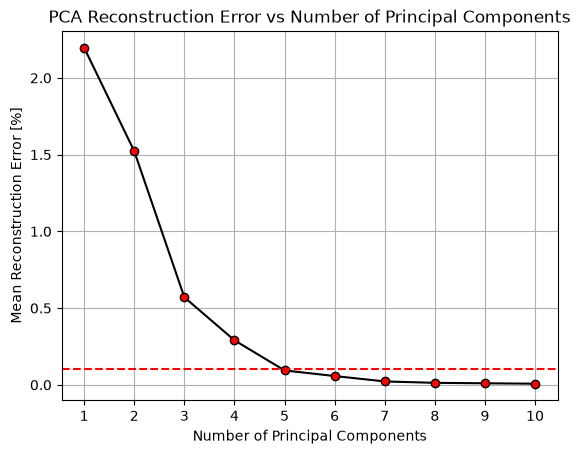

In [84]:
# Test optimal number of PCA components
errors = []
for n_components in range(1, 11):
    error_avg, error_all = pca_reconstruction_error(U, n_components)
    errors.append(error_avg)
    print(f"n_components: {n_components}, error_avg: {error_avg:.4f}")

plot_pca_reconerror(errors)

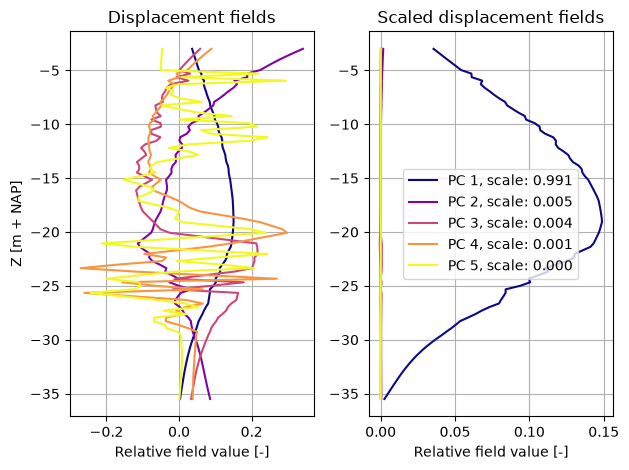

In [92]:
# Calculate field displacement
pc_fields, pc_fields_scaled, importance = pca_displacement_field(U, 5)

plot_pca_fields(pc_fields, pc_fields_scaled, importance, Z)

In [86]:
# Trial and error analysis for Sobol indices
n_trials = 1000
n_modes = 5
n_degrees = 10

run = False # change to True to run the Sobol error trials (takes ~5 min for 1000 trials)

if run:
      R2, RMSE, GNAE, sobol_first, sobol_total \
      = sobol_error_trials(n_trials=n_trials, n_modes=n_modes, n_degrees=n_degrees, X_raw=X, U=U, n_vars=2)

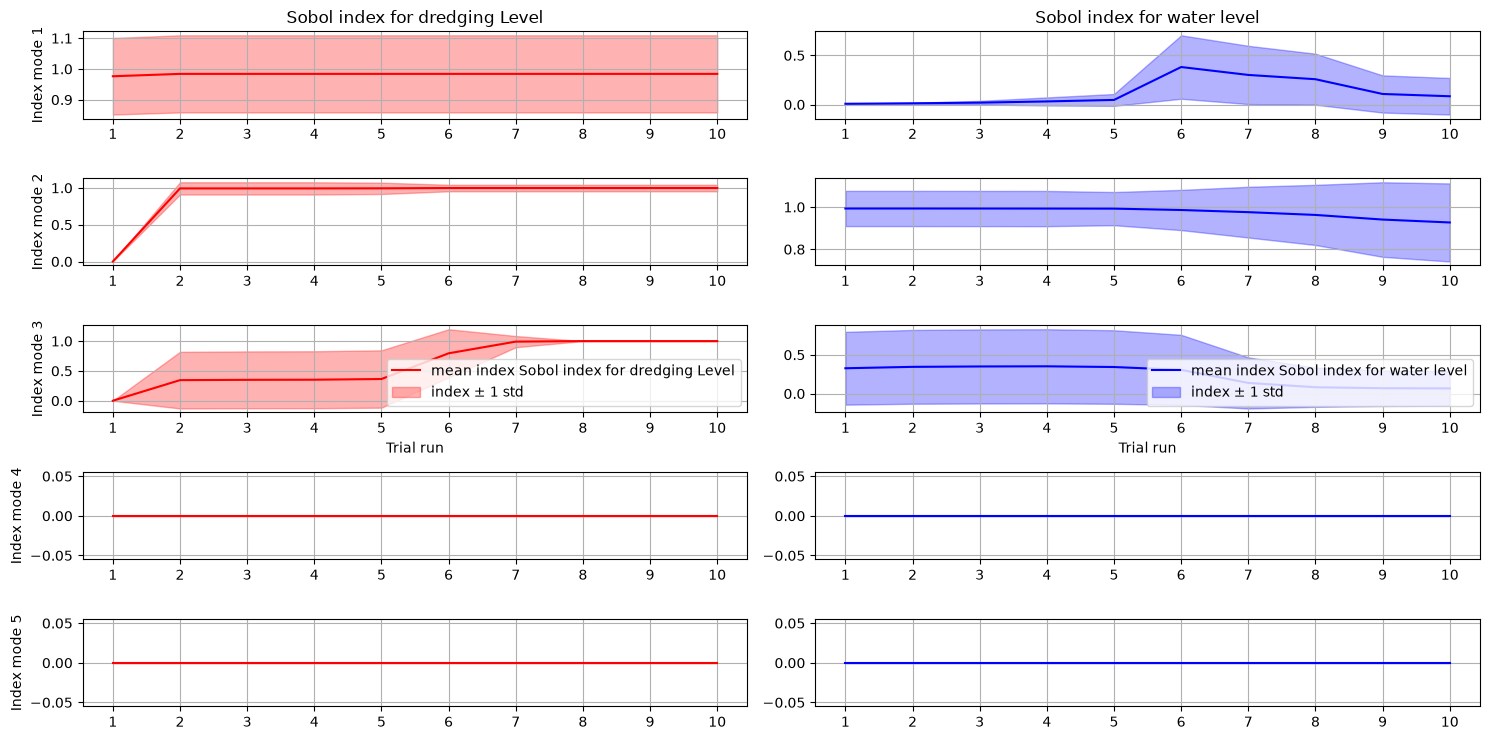

In [87]:
plot_sobol_indices_ps()

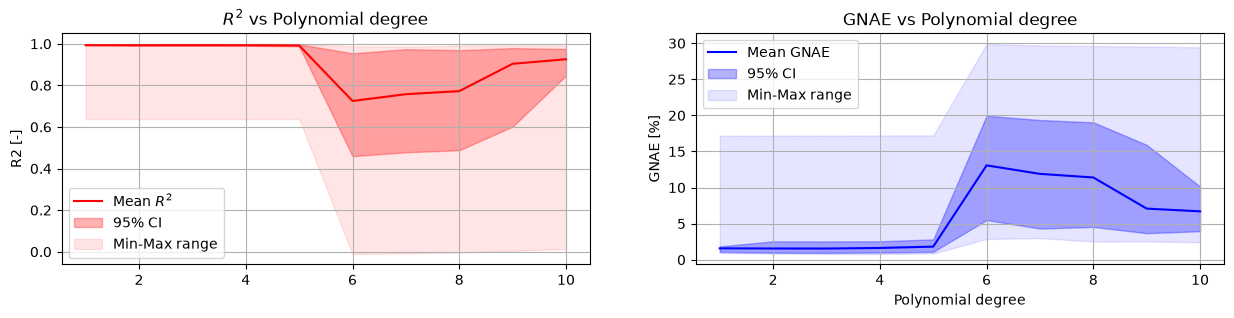

In [88]:
plot_errors("Parametric_Study_Surrogate")

In [ ]:
# Predictive model for parametric study surrogate
X_train_val, X_test_val, U_train_val, U_test_val = train_test_split(X, U, test_size=0.2, random_state=42)
X_train = ot.Sample(X_train_val)
X_test = ot.Sample(X_test_val)
U_train = ot.Sample(U_train_val)
U_test = ot.Sample(U_test_val)

pce_models, pca, results = train_PCE_ps(X_train, U_train, total_degree=5, n_components=5)

# Saving model
study = ot.Study()
study.setStorageManager(ot.XMLStorageManager("Logs\\Parametric_Study_Surrogate\\calsur_pce_model.xml"))

## Save PCE model per mode
for i, model in enumerate(pce_models):
    model_i = results[i].getMetaModel()
    study.add(f"pce_model_mode_{i+1}", model_i)
    study.save()
dump(pca, "Logs\\Parametric_Study_Surrogate\\calsur_pca_model.joblib")

['Logs\\Parametric_Study_Surrogate\\calsur_pca_model.joblib']

Text(0.5, 1.0, 'Predicted deformation for test input [-2, -20]')

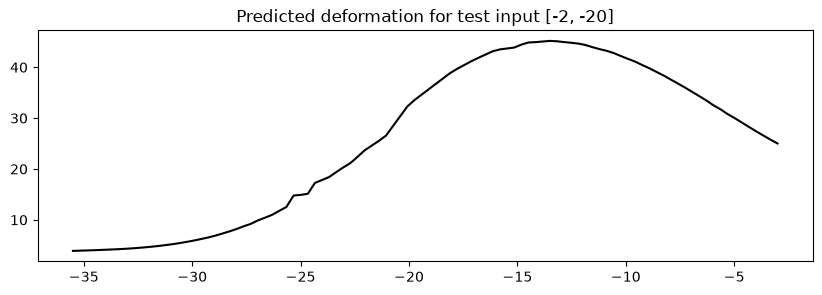

In [90]:
# Load model (not necessary if just trained, but useful for complicated models or multiple models)
study = ot.Study()
study.setStorageManager(
ot.XMLStorageManager("Logs\\Parametric_Study_Surrogate\\calsur_pce_model.xml")
)

n_modes = 4

study.load()

## PCE models per mode
models = []
for i in range(1, n_modes + 1):
    mode_i_model = ot.Function()
    study.fillObject(f"pce_model_mode_{i}", mode_i_model) 
    models.append(mode_i_model)

# Model prediction for a given test input
x_test = [-2, -20]

a_pred = np.array([model(x_test)[0] for model in models]).reshape(1, -1)
pca_loaded = load("Logs\\Parametric_Study_Surrogate\\calsur_pca_model.joblib")

predict_test = pca_loaded.inverse_transform(a_pred)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(Z, predict_test[0], label='Predicted', color='k')
ax.set_title(f"Predicted deformation for test input {x_test}")

min R_sq:          0.972
GNEA:              1.632%
max difference:    5.91 mm, between FEM and PCE


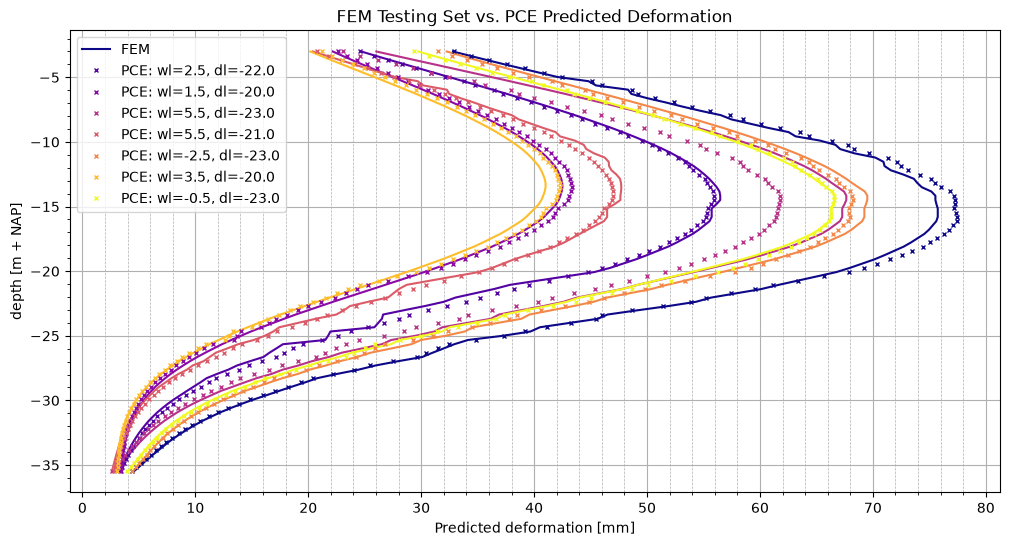

In [91]:
errors = []
R_sq = []
GNEA = []
n = U_test_val.shape[0] ## number of test samples to display
maxdif = []

U_meas = import_measurements("Logs\\inclino.csv", Z)
errors, R_sq, GNEA, maxdif = test_model_ps(pca_loaded, models, X_test_val, U_test_val, Z)

print(f"min R_sq: {np.min(R_sq):>14.3f}")
print(f"GNEA: {np.mean(GNEA):>18.3f}%")
print(f"max difference: {np.max(maxdif):>7.2f} mm, between FEM and PCE")